# Лабиринт и программируемая мышка
Движение выполняется только через Game: `up()`, `right()`, `down()` и `left()`. Каждая команда делает одну попытку шага.

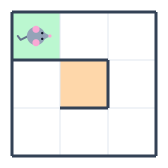

In [3]:
from IPython.display import display
from labyrinth import Direction, Game, Grid, PlaceObject, SpiralMaze
from labyrinth_view import MazeView

maze = SpiralMaze(3, 3)
game = Game(maze)
view = MazeView(game)
display(view)

In [5]:
game.reset()

In [ ]:
from time import sleep

game.reset()
commands = {Direction.UP: game.up, Direction.RIGHT: game.right,
            Direction.DOWN: game.down, Direction.LEFT: game.left}
route = [next(d for d in Direction if d.delta == (b[0] - a[0], b[1] - a[1]))
         for a, b in zip(maze.spiral_path, maze.spiral_path[1:])]
for direction in route:
    if not commands[direction]():
        break
    sleep(0.03)
print('Игра окончена:', game.finished)

## Объекты и закрытые рёбра
Grid не знает стен. Любой объект с `blocks_movement=True` закрывает содержащий его Place.

In [ ]:
my_grid = Grid(6, 4, exit=(5, 3))
barrier = PlaceObject(blocks_movement=True)
my_grid.place_between((0, 0), 'right', barrier)
my_game = Game(my_grid)
my_view = MazeView(my_game)
display(my_view)
print(my_game.right())  # False
my_grid.remove_between((0, 0), 'right', barrier)
print(my_game.right())  # True

In [ ]:
events = []
my_game.subscribe_event(events.append)
my_game.exit = my_game.mouse.position
print(events)